# Predicting Bike Rentals

<div>
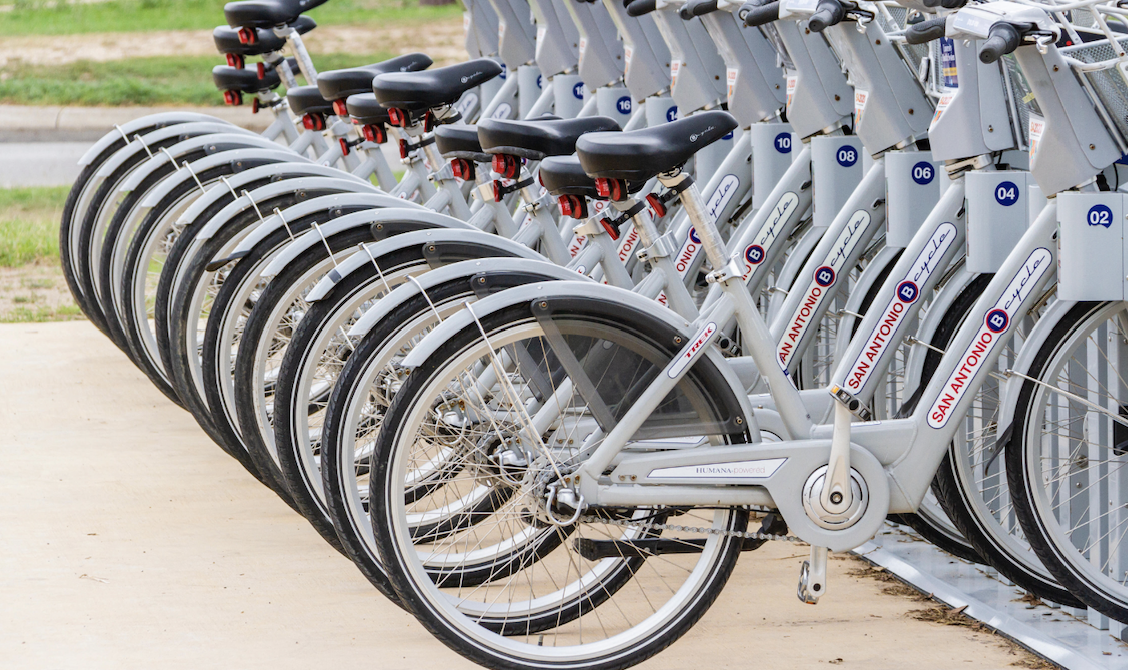
</div>

## Introduction

In this project we will be working with a dataset on bike rentals. Bike sharing has become very common in cities in the United States and the dataset we are working with is data from a bike sharing station where you can rent bicycles by the hour or day in Washington D.C. 

Hadi Fanaee-T at the University of Porto compiled this data into a CSV file, which we'll work with in this project. The file contains 17380 rows, with each row representing the number of bike rentals for a single hour of a single day. You can download the data from <a href='http://archive.ics.uci.edu/ml/datasets/Bike+Sharing+Dataset'> the University of California, Irvine's website</a>.

Here are the descriptions for the relevant columns:

* `instant` - A unique sequential ID number for each row
* `dteday` - The date of the rentals
* `season` - The season in which the rentals occurred
* `yr` - The year the rentals occurred
* `mnth` - The month the rentals occurred
* `hr` - The hour the rentals occurred
* `holiday` - Whether or not the day was a holiday
* `weekday` - The day of the week (as a number, 0 to 7)
* `workingday` - Whether or not the day was a working day
* `weathersit` - The weather (as a categorical variable)
* `temp` - The temperature, on a 0-1 scale
* `atemp` - The adjusted temperature
* `hum` - The humidity, on a 0-1 scale
* `windspeed` - The wind speed, on a 0-1 scale
* `casual` - The number of casual riders (people who hadn't previously signed up with the bike sharing program)
* `registered` - The number of registered riders (people who had already signed up)
* `cnt` - The total number of bike rentals (casual + registered)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.style as style
import numpy as np
style.use('seaborn')
%matplotlib inline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor


In [4]:
# initializing the models
lr = LinearRegression()
dt = DecisionTreeRegressor(random_state=1)
rf = RandomForestRegressor(random_state=1)

## Data Exploration

In [6]:
bikes = pd.read_csv('bike_rental_hour.csv')
bikes

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [7]:
bikes.corr()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
instant,1.000000,0.404046,0.866014,0.489164,-0.004775,0.014723,0.001357,-0.003416,-0.014198,0.136178,0.137615,0.009577,-0.074505,0.158295,0.282046,0.278379
season,0.404046,1.000000,-0.010742,0.830386,-0.006117,-0.009585,-0.002335,0.013743,-0.014524,0.312025,0.319380,0.150625,-0.149773,0.120206,0.174226,0.178056
yr,0.866014,-0.010742,1.000000,-0.010473,-0.003867,0.006692,-0.004485,-0.002196,-0.019157,0.040913,0.039222,-0.083546,-0.008740,0.142779,0.253684,0.250495
mnth,0.489164,0.830386,-0.010473,1.000000,-0.005772,0.018430,0.010400,-0.003477,0.005400,0.201691,0.208096,0.164411,-0.135386,0.068457,0.122273,0.120638
hr,-0.004775,-0.006117,-0.003867,-0.005772,1.000000,0.000479,-0.003498,0.002285,-0.020203,0.137603,0.133750,-0.276498,0.137252,0.301202,0.374141,0.394071
holiday,0.014723,-0.009585,0.006692,0.018430,0.000479,1.000000,-0.102088,-0.252471,-0.017036,-0.027340,-0.030973,-0.010588,0.003988,0.031564,-0.047345,-0.030927
weekday,0.001357,-0.002335,-0.004485,0.010400,-0.003498,-0.102088,1.000000,0.035955,0.003311,-0.001795,-0.008821,-0.037158,0.011502,0.032721,0.021578,0.026900
workingday,-0.003416,0.013743,-0.002196,-0.003477,0.002285,-0.252471,0.035955,1.000000,0.044672,0.055390,0.054667,0.015688,-0.011830,-0.300942,0.134326,0.030284
weathersit,-0.014198,-0.014524,-0.019157,0.005400,-0.020203,-0.017036,0.003311,0.044672,1.000000,-0.102640,-0.105563,0.418130,0.026226,-0.152628,-0.120966,-0.142426
temp,0.136178,0.312025,0.040913,0.201691,0.137603,-0.027340,-0.001795,0.055390,-0.102640,1.000000,0.987672,-0.069881,-0.023125,0.459616,0.335361,0.404772


Since the other variables have a linear correlation with the `cnt` column, we are going to use a regression model. We are also going to transform the hour columns to represent morning, afternoons, evenings and night since the different hours have a relationship with each other.

In [8]:
# function classifies different hours in the dataset into morning (1), afternoon (2), evening (3) and night (4).
def time_label(hour):
    if hour > 6 and hour <= 12:
        return 1
    elif hour > 12  and hour <= 18:
        return 2
    elif hour > 18 and hour <= 24:
        return 3
    else:
        return 4
    

In [9]:
bikes['time_label'] = bikes['hr'].apply(time_label)
bikes.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,time_label
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,4
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,4
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,4
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,4
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,4


## Testing Out Different Regression Models
We are going to be training the model using linear regression, decision tree regressor and random forest regressor and then compare the performances of each of them.

I also imported two classes from a previous project, `FeatureSelection` and `FeaturePrediction` respectively. The first will be used to split the dataset into train and test samples. The DataFrame is first randomised before it is split. The latter will be used to get our error values. I've decided to work with `mean absolute error` as my error metric instead of the `root mean squared error` returned by the class. For this reason I created the `BikePrediction` class which inherits from the `FeaturePrediction` class.

In [25]:
# classes from a previous project
from Predicting_house_prices import FeatureSelection, FeaturePrediction

In [26]:
train, test = FeatureSelection.train_test(bikes, 0.2)

In [30]:
print(f'train dataset {train.shape}')
print(f'train dataset {test.shape}')

train dataset (13904, 18)
train dataset (3475, 18)


In [31]:
class BikePrediction(FeaturePrediction):
    def mae(self, model):
        from sklearn.metrics import mean_absolute_error
        predictions = self.predict(model)
        error = mean_absolute_error(self.get_target()[1], predictions)
        
        return error
    
    
        

In [32]:
predictors = train.columns.drop(['cnt', 'casual', 'registered', 'hr', 'instant', 'dteday'])

In [33]:
# training the model using linear regression
lr_error = BikePrediction(train, test, predictors, 'cnt').mae(lr)
print('test set: ', lr_error)

lr_train_error = BikePrediction(train, train, predictors, 'cnt').mae(lr)
print('train set: ', lr_train_error)

test set:  99.0647971051442
train set:  98.332671834548


The linear regression model seems to fit the data properly. We can see this as there isn't a lot of different in the error between the test set and the train set.

In [34]:
# training the model using decision trees
dt_error = BikePrediction(train, test, predictors, 'cnt').mae(dt)
print('test set: ', dt_error)

dt_train_error = BikePrediction(train, train, predictors, 'cnt').mae(dt)
print('train set: ', dt_train_error)

test set:  85.24520863309351
train set:  3.588991177598772


When we used decision trees, we ended up with a lower error on the test set but the difference between the train set error and the test set error is so significant. This is  a sign that the decision trees model is overfitting the data.

In [35]:
rf_error = BikePrediction(train, test, predictors, 'cnt').mae(rf)
print('test set: ', rf_error)

rf_train_error = BikePrediction(train, train, predictors, 'cnt').mae(rf)
print('train set: ', rf_train_error)

test set:  68.09851059796318
train set:  27.301729582090807


With the random forest model, we managed to reduce the error again and overfit less than in the decision trees but the model still overfits the data.

## Parameter Tuning Of Decision Tree Model
We are going to create fucntions that displays a plot of the difference between the train set error and the test set error. The reason for using functions is because we will be using the same names for the variables in the local scope of the fucntions. This prevents us from overwriting the variable. Here we are going to do the following:

* Display the difference in the error values as we change the `min_samples_leaf` parameter from 1 to 14.
* Display the difference in the error values as we change the `max_depth` parameter from 1 to 14.
* Display the difference in the error values as we change the `min_samples_leaf` and `max_depth` parameter by choosing random values between 1 and 14.

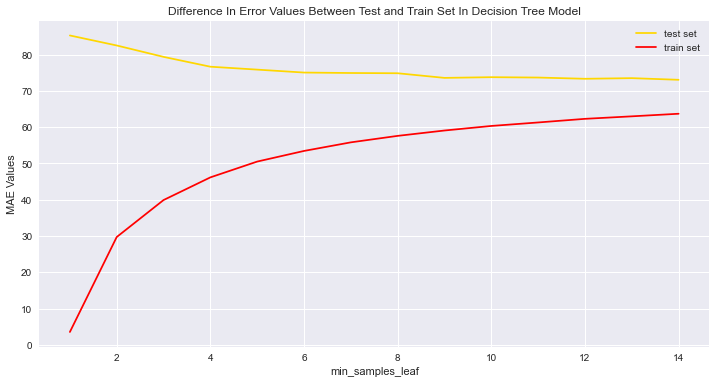

In [36]:
def samples_leaf_tuning():
    test_set = []
    train_set = []
    for i in range (1, 15):
        dt = DecisionTreeRegressor(random_state=1, min_samples_leaf=i)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(dt))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(dt))
    
    plt.figure(figsize=(12, 6))
    x = np.arange(1, 15)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('min_samples_leaf')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Decision Tree Model')
    plt.show()
    

samples_leaf_tuning()
        

As we increased the `min_samples_leaf` value from 1 to 14, the difference in the error between the train and test set reduced, we can see this as the lines for the train and test set error begin to converge towards each other. The model overfits less as we increase the minimum samples leaf.

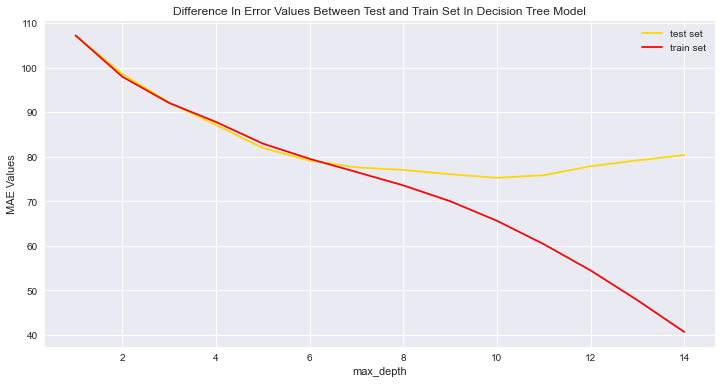

In [37]:
def max_depth_tuning():
    test_set = []
    train_set = []
    for i in range (1, 15):
        dt = DecisionTreeRegressor(random_state=1, max_depth=i)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(dt))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(dt))

    plt.figure(figsize=(12, 6))
    x = np.arange(1, 15)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('max_depth')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Decision Tree Model')
    plt.show()
    
max_depth_tuning()
    

When we tuned the `max_depth` parameter, the initial error values are higher for both the train and test set, this is usually a sign that the model is underfitting the data. As th max depth increased both test set and train set error values reduces and the model begins to fit optimally. The error values for both the test set and train set error begin to grow significantly apart as the max depth exceeds 8.

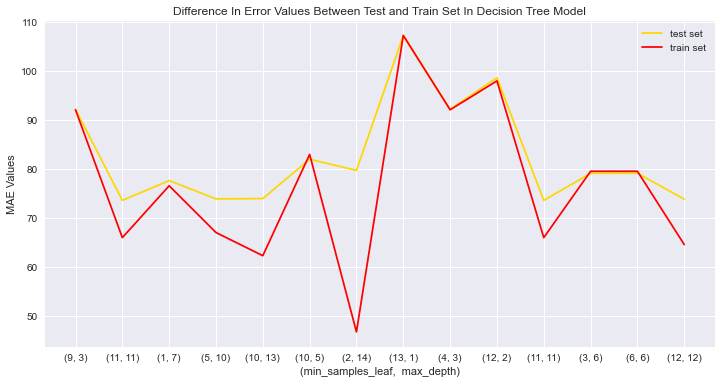

In [38]:
def multi_params_decisiontree_tuning():
    test_set = []
    train_set = []
    params = []
    for i in range (1, 15):
        min_samples_leaf= np.random.choice(range(1, 15))
        max_depth= np.random.choice(range(1, 15))
        params.append((min_samples_leaf, max_depth))

        dt = DecisionTreeRegressor(random_state=1, min_samples_leaf=min_samples_leaf, 
                                   max_depth=max_depth)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(dt))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(dt))

    plt.figure(figsize=(12, 6))
    x = np.arange(1, 15)
    plt.xticks(x, params)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('(min_samples_leaf,  max_depth)')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Decision Tree Model')
    plt.show()
    
multi_params_decisiontree_tuning()

Here we used a combination of random values between 1 and 14 for both the `min_samples_leaf` and `max_depth` parameters. For most of the combinations, there wasn't a huge difference between  the error values for the train and test set. Tuning multiple parameters reduces the error and also reduces how much the model overfits.

## Parameter Tuning For Random Forest Model
We are going to repeat the process used for the decision trees model here.

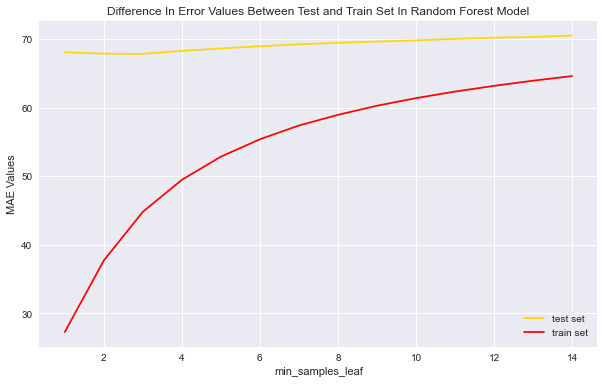

In [39]:
def randomforest_samples_leaf():
    test_set = []
    train_set = []
    for i in range (1, 15):
        rf = RandomForestRegressor(random_state=1, min_samples_leaf=i)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(rf))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(rf))
    
    plt.figure(figsize=(10, 6))
    x = np.arange(1, 15)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('min_samples_leaf')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Random Forest Model')
    plt.show()
    

randomforest_samples_leaf()

We have an almost identical behaviour to the decision tree model when we tune the `min_samples_leaf` parameter for the random forest model. Although the the difference between the test  and train sets is initially smaller than that of the decision tree model, it was still clearly overfitting. As the minimum samples leaf increased, the difference between the train and test set errors reduced but this time instead of both train and test set errors converging into each other, the test set error fairly remanined the same, reducing only slightly while the train set error increased significantly and reduced the difference between the train and test set errors. 

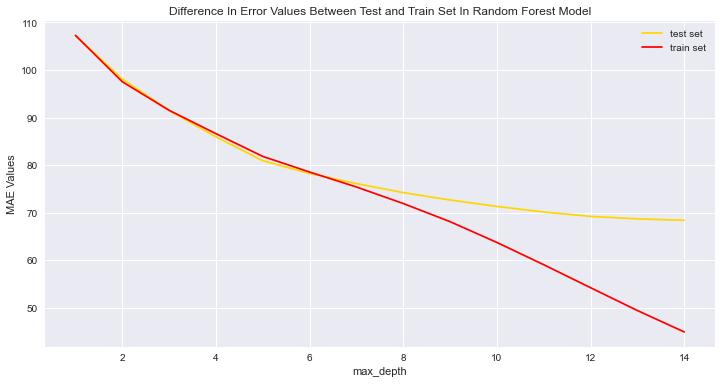

In [40]:
def randomforest_max_depth():
    test_set = []
    train_set = []
    for i in range (1, 15):
        rf = RandomForestRegressor(random_state=1, max_depth=i)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(rf))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(rf))

    plt.figure(figsize=(12, 6))
    x = np.arange(1, 15)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('max_depth')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Random Forest Model')
    plt.show()
    
randomforest_max_depth()
    

When we adjust `max_depth` for the random forest model, we get a similar story to that of decision tree model. It underfits at first and then both the test and train set errors reduce as the value for `max_depth` increases. In general the random forest model tend to have a slightly lower error value than that of the decision tree and also overfits less.

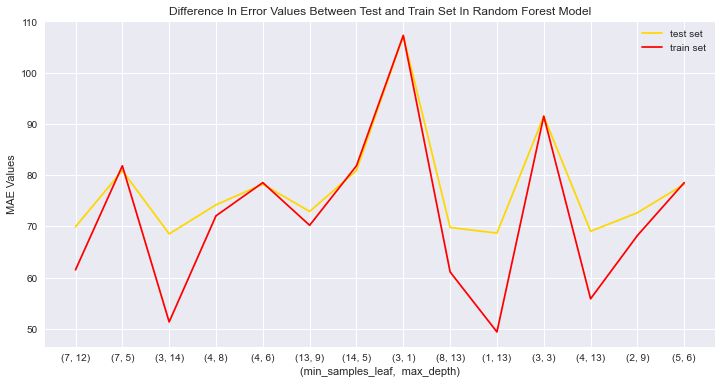

In [41]:
def multi_params_randomforest_tuning():
    test_set = []
    train_set = []
    params = []
    for i in range (1, 15):
        min_samples_leaf= np.random.choice(range(1, 15))
        max_depth= np.random.choice(range(1, 15))
        params.append((min_samples_leaf, max_depth))

        rf = RandomForestRegressor(random_state=1, min_samples_leaf=min_samples_leaf, 
                                   max_depth=max_depth)
        test_set.append(BikePrediction(train, test, predictors, 'cnt').mae(rf))
        train_set.append(BikePrediction(train, train, predictors, 'cnt').mae(rf))

    plt.figure(figsize=(12, 6))
    x = np.arange(1, 15)
    plt.xticks(x, params)
    plt.plot(x, test_set, label='test set', color='gold')
    plt.plot(x, train_set, label ='train set', color='red')
    plt.xlabel('(min_samples_leaf,  max_depth)')
    plt.ylabel('MAE Values')
    plt.legend()
    plt.title('Difference In Error Values Between Test and Train Set In Random Forest Model')
    plt.show()
    
multi_params_randomforest_tuning()

In general adjusting both parameters resulted in lower errors and less overfitting.

## Conclusion
From what we saw, both decision tree and random forest model had a lower error value on the test set than the linear regression model. But they tend to overfit the data, the decision tree model more so than the random forest model. Tuning the parameters resulted in both a lower error value and also less overfitting.